Accuracy  : 65.83333333333333 %


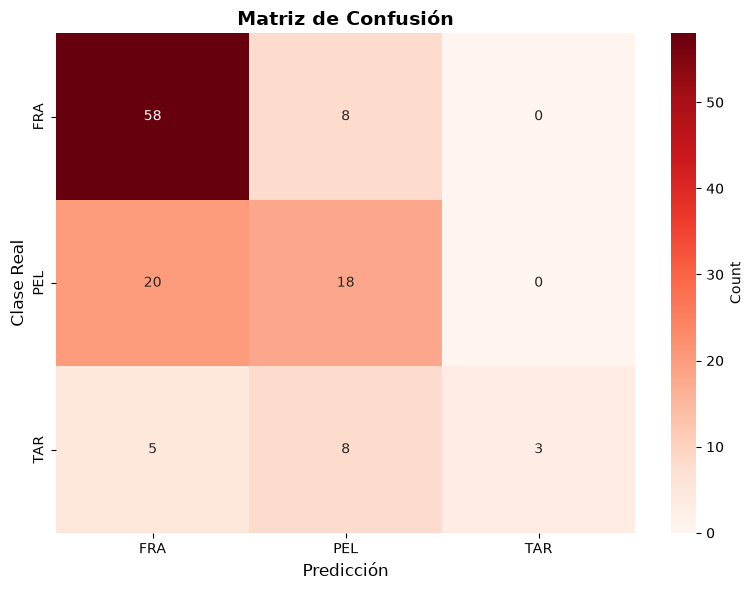

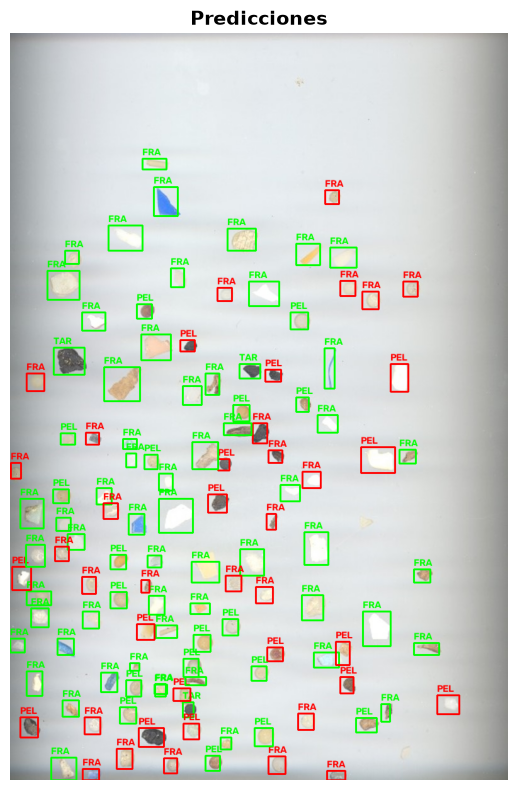

In [3]:
import cv2
import csv
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

train_imgs = {
    "FRA": "FRA.png",
    "PEL": "PEL.png",
    "TAR": "TAR.png"
}

test = "test.jpg"
test_csv = "MPs_test_bbs.csv"

# Función que extrae las características de la imagen
def extract_features(img):
    
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # Umbralizamos la imagen con Otsu
    _, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    # Buscamos el fondo de la imagen "mask == 255 pixeles blancos | mask == 0 pixeles negros".
    # En caso de tener un fondo blanco, incertiremos los valores de la imagen umbralizada para
    # que las partículas tengan color blanco y el fondo sea negro.
    if np.mean(gray[mask == 255]) > np.mean(gray[mask == 0]):
        mask = cv2.bitwise_not(mask)
    
    # Buscamos los contornos
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # Seleccionamos el contorno más grande
    cnt = max(contours, key=cv2.contourArea)
    
    # Obtenemos las características del contorno
    x, y, w, h = cv2.boundingRect(cnt)
    area = cv2.contourArea(cnt)
    perimeter = cv2.arcLength(cnt, True)
    compacidad = (perimeter ** 2) / (area + 1e-9)
    rel_area_box = area / (w * h + 1e-9)
    aspect_ratio = w / (h + 1e-9)
    
    # Elipse:
    # Comprobamos que el contorno sea al menos de 5 puntos ya que este es el mínimo de "fitEllipse()"
    if len(cnt) >= 5:
        try:
            (_, _), (MA, ma), _ = cv2.fitEllipse(cnt) #Obtenemos las longitudes de los ejes
            rel_ejes = max(MA, ma) / (min(MA, ma) + 1e-9) #Ejes similares: ~= 1 | Eje mayor que otro: > 1
        except:
            rel_ejes = 0
    else:
        rel_ejes = 0
    
    # Centroide:
    # Utilizamos el momento para obtener las coordenadas horizontales y verticales.
    # El momento de orden cero (00) se relacciona con el area
    # El momento de primer orden (10) se relacciona con la coordenada horizontal
    # El momento de primer orden (01) se relacciona con la coordenada vertical
    M = cv2.moments(cnt)
    
    # Evitamos el error de dividir entre 0
    if M["m00"] != 0:
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])
    else:
        cx, cy = 0, 0
    
    # Distancias desde el centroide hasta el contorno
    # "cv2.norm" Calcula la norma del vector resultante. d = sqrt[(cx-x)^2+(cy-y)^2]

    dists = [cv2.norm(np.array([cx, cy], dtype=np.float32) - p[0].astype(np.float32)) for p in cnt]
    rel_dist = min(dists) / (max(dists) + 1e-9) if len(dists) > 0 else 0
    
    # Colores:
    # Medidas RGB de la imagen
    mean_b = np.mean(img[mask == 255, 0]) if np.any(mask == 255) else 0
    mean_g = np.mean(img[mask == 255, 1]) if np.any(mask == 255) else 0
    mean_r = np.mean(img[mask == 255, 2]) if np.any(mask == 255) else 0
    
    # Desviación estándar RGB de la imagen
    std_b = np.std(img[mask == 255, 0]) if np.any(mask == 255) else 0
    std_g = np.std(img[mask == 255, 1]) if np.any(mask == 255) else 0
    std_r = np.std(img[mask == 255, 2]) if np.any(mask == 255) else 0
    
    # Media, saturación y brillo de la imagen
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mean_h = np.mean(hsv[mask == 255, 0]) if np.any(mask == 255) else 0
    mean_s = np.mean(hsv[mask == 255, 1]) if np.any(mask == 255) else 0
    mean_v = np.mean(hsv[mask == 255, 2]) if np.any(mask == 255) else 0
    
    # Solidez
    hull = cv2.convexHull(cnt)
    hull_area = cv2.contourArea(hull)
    solidity = area / (hull_area + 1e-9)
    
    # Extensión
    extent = area / (w * h + 1e-9)
    
    return [
        area, perimeter, compacidad, rel_area_box, aspect_ratio, rel_ejes, rel_dist,
        mean_r, mean_g, mean_b, std_r, std_g, std_b,
        mean_h, mean_s, mean_v, solidity, extent
    ]


# Extraemos las características de entrenamiento
patterns = {}
X_train = []
y_train = []

for label, path in train_imgs.items():
    img = cv2.imread(path)
    features = extract_features(img)
    patterns[label] = np.array(features)
    X_train.append(features)
    y_train.append(label)

# Normalizamos las características
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Entrenamiento del clasificador "Random Forest":
# n_estimators: indica el número de árboles de decisión que tendrá el bosque
# random_state: se le da un valor para la aletoriedad (semilla)
# max_depth: profundidad máxima de cada árbol
clf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
# Entrenamiento
clf.fit(X_train_scaled, y_train)

# Imagen de prueba
img_test = cv2.imread(test)
y_true = []
y_pred = []

# Leemos el csv con los datos de la imagen
with open(test_csv, newline="") as file:
    reader = csv.DictReader(file)
    for row in reader:
        label = row["label"]
        
        #Obtenemos las coordenadas
        x_min, y_min, x_max, y_max = map(int, [
            row["x_min"], row["y_min"], row["x_max"], row["y_max"]
        ])
        
        # Recortamos la partícula que se encuentra en las siguientes coordenadas:
        crop = img_test[y_min:y_max, x_min:x_max]
        # Obtenemos las características de la partícula recortada
        features = extract_features(crop)
        
        if features is None:
            pred = "FRA"
        else:
            # Se aplica al vector de características los mismos parámetros de estandarización 
            # aprendidos durante el entrenamiento.
            features_scaled = scaler.transform([features])
            # Se predice la etiqueta de la partícula
            pred = clf.predict(features_scaled)[0]
        
        y_true.append(label)
        y_pred.append(pred)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

print(f"Accuracy  :", accuracy*100,"%")

# Matriz confusión
labels = ["FRA", "PEL", "TAR"]
cm = confusion_matrix(y_true, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds",
            xticklabels=labels, yticklabels=labels, cbar_kws={'label': 'Count'})
plt.xlabel("Predicción", fontsize=12)
plt.ylabel("Clase Real", fontsize=12)
plt.title("Matriz de Confusión", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Imagen
colores = {"FRA": (0, 0, 255), "PEL": (0, 255, 0), "TAR": (255, 0, 0)}
img_display = img_test.copy()

with open(test_csv, newline="") as file:
    reader = csv.DictReader(file)
    for i, row in enumerate(reader):
        x_min, y_min, x_max, y_max = map(int, [
            row["x_min"], row["y_min"], row["x_max"], row["y_max"]
        ])
        pred = y_pred[i]
        true_label = y_true[i]
        
        # Color: green if correct, red if incorrect
        is_correct = (pred == true_label)
        color = (0, 255, 0) if is_correct else (0, 0, 255)
        
        cv2.rectangle(img_display, (x_min, y_min), (x_max, y_max), color, 2)
        cv2.putText(img_display, f"{pred}", (x_min, y_min - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(img_display, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Predicciones", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()